# Transformer Performance Tests

In [1]:
import sys
from pathlib import Path

ROOT = Path().resolve().parents[0]
sys.path.append(str(ROOT))
sys.path.append(str(ROOT / "src" / "data_generation"))
sys.path.append(str(ROOT / "src" / "models"))
sys.path.append(str(ROOT / "src" / "evaluation"))

In [2]:
# Required adding .vscode/settings.json to get highlighting to work!
from room_dataset import RoomDataset, collate_rooms, load_rooms_as_descriptions
from transformer import FurnitureEmbeddingPredictor, TransformerEvaluator
from evaluator import LeaveOneOutEvaluator
from baseline_models import ItemContentBaseline, ItemItemCooccurrence, PopularityPrior

import torch, numpy as np, matplotlib.pyplot as plt, pandas as pd
from torch.utils.data import Dataset, DataLoader

In [3]:
# Training Configuration ==================================
DATASET = "synthetic"   # "df_captions", "df_short", or "synthetic"
LABELED = True            # True = include room_type label token at slot 0; False = unlabeled
FORCE_TRAINING = False
LOSS = "infonce"          # in-batch InfoNCE
NUM_LAYERS = 3
NUM_HEADS = 13
HID_DIM = 768
DROPOUT = 0.1
EPOCHS = 15

train_dataset = RoomDataset("train", labeled=LABELED, dataset=DATASET)
val_dataset = RoomDataset("val", labeled=LABELED, dataset=DATASET)
test_dataset = RoomDataset("test", labeled=LABELED, dataset=DATASET)

def collate_fn(batch):
    return collate_rooms(batch, labeled=LABELED)

def make_dataloader(dataset, shuffle=True) -> DataLoader:
    return DataLoader(
        dataset,
        batch_size=256,
        shuffle=shuffle,
        collate_fn=collate_fn,
    )

train_loader = make_dataloader(train_dataset, shuffle=True)
val_loader = make_dataloader(val_dataset, shuffle=False)
test_loader = make_dataloader(test_dataset, shuffle=False)

model = FurnitureEmbeddingPredictor(
    nhead=4,
    num_candidates=NUM_HEADS,
    num_layers=NUM_LAYERS,
    hid_dim=HID_DIM,
    dropout=DROPOUT,
)

label_tag = "labeled" if LABELED else "unlabeled"
model_filename = f"{DATASET}_{label_tag}.pt"

try:
    if FORCE_TRAINING:
        print(f"Forcing training ({model_filename})")
        model.fit(
            train_loader,
            val_loader=val_loader,
            labeled_data=LABELED,
            epochs=EPOCHS,
            lr=1.5e-4,
            plot_every=10,
            loss_type=LOSS,
        )
        torch.save(model.state_dict(), str(ROOT / "notebooks" / model_filename))
    else:
        model.load_state_dict(torch.load(str(ROOT / "notebooks" / model_filename), weights_only=True))

except FileNotFoundError:
    print(f"{model_filename} not found on disk, training...")
    model.fit(
        train_loader,
        val_loader=val_loader,
        labeled_data=LABELED,
        epochs=EPOCHS,
        lr=1.5e-4,
        plot_every=10,
        loss_type=LOSS,
    )
    torch.save(model.state_dict(), str(ROOT / "notebooks" / model_filename))
except KeyboardInterrupt:
    print("Keyboard Interrupt detected, saving...")
    torch.save(model.state_dict(), str(ROOT / "notebooks" / model_filename))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loaded instance on device: mps with 13 candidate head(s)


Loaded instance on device: mps with 13 candidate head(s)
Loading weights from synthetic_labeled.pt...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]


Evaluating on 1000 validation rooms (k=5)...
Evaluating Popularity Prior...


100%|██████████| 1000/1000 [00:00<00:00, 18826.77it/s]


Evaluating Item-Item Co-occurrence...


100%|██████████| 1000/1000 [00:00<00:00, 9559.95it/s]


Evaluating Transformer...


100%|██████████| 1000/1000 [00:07<00:00, 135.87it/s]



--- Evaluation Summary Table ---
           Model Exact R@5 Exact NDCG@5 Category R@5 Category NDCG@5 Semantic Sim Semantic R@5
Popularity Prior    0.0520       0.0277       0.2280          0.2280       0.6706       0.1560
      ItemItemCo    0.0630       0.0365       0.7630          0.6299       0.7705       0.2530
     Transformer    0.0700       0.0402       0.9660          0.9123       0.8351       0.3600


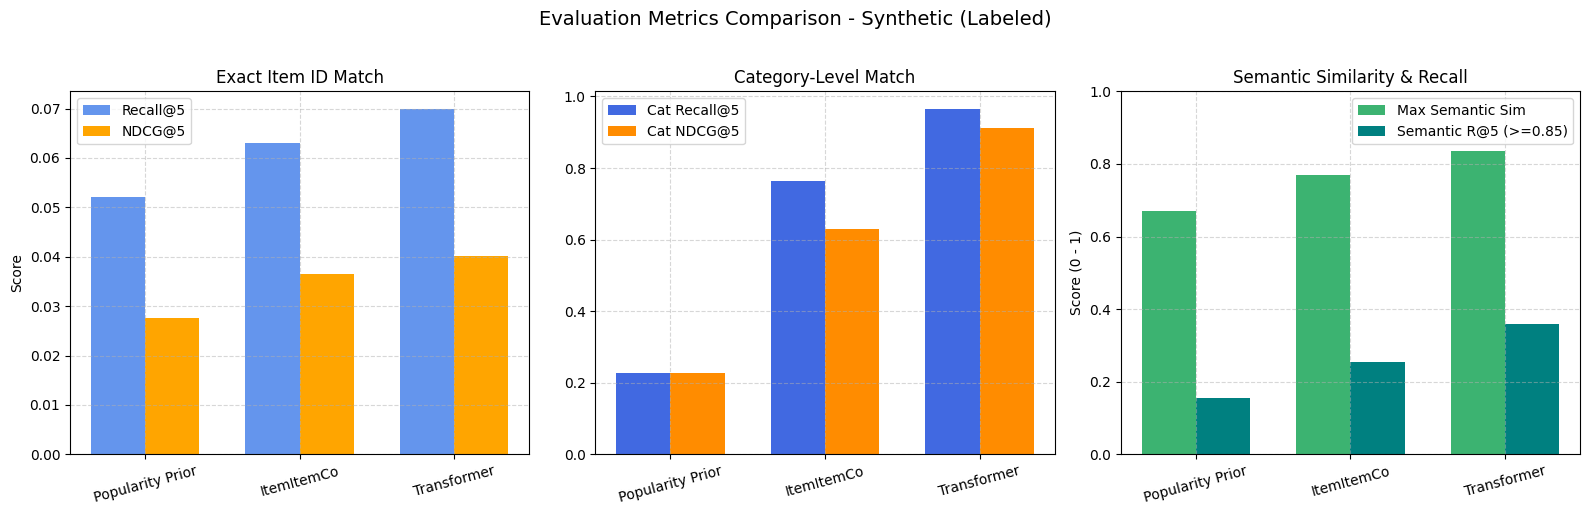

Loaded instance on device: mps with 13 candidate head(s)
Loading weights from synthetic_unlabeled.pt...

Evaluating on 1000 validation rooms (k=5)...
Evaluating Popularity Prior...


100%|██████████| 1000/1000 [00:00<00:00, 18819.93it/s]


Evaluating Item-Item Co-occurrence...


100%|██████████| 1000/1000 [00:00<00:00, 8137.30it/s]


Evaluating Transformer...


100%|██████████| 1000/1000 [00:06<00:00, 145.31it/s]



--- Evaluation Summary Table ---
           Model Exact R@5 Exact NDCG@5 Category R@5 Category NDCG@5 Semantic Sim Semantic R@5
Popularity Prior    0.0200       0.0110       0.0450          0.0450       0.6209       0.0360
      ItemItemCo    0.0560       0.0331       0.5380          0.4226       0.7304       0.1980
     Transformer    0.0590       0.0342       0.9580          0.8959       0.8218       0.3330


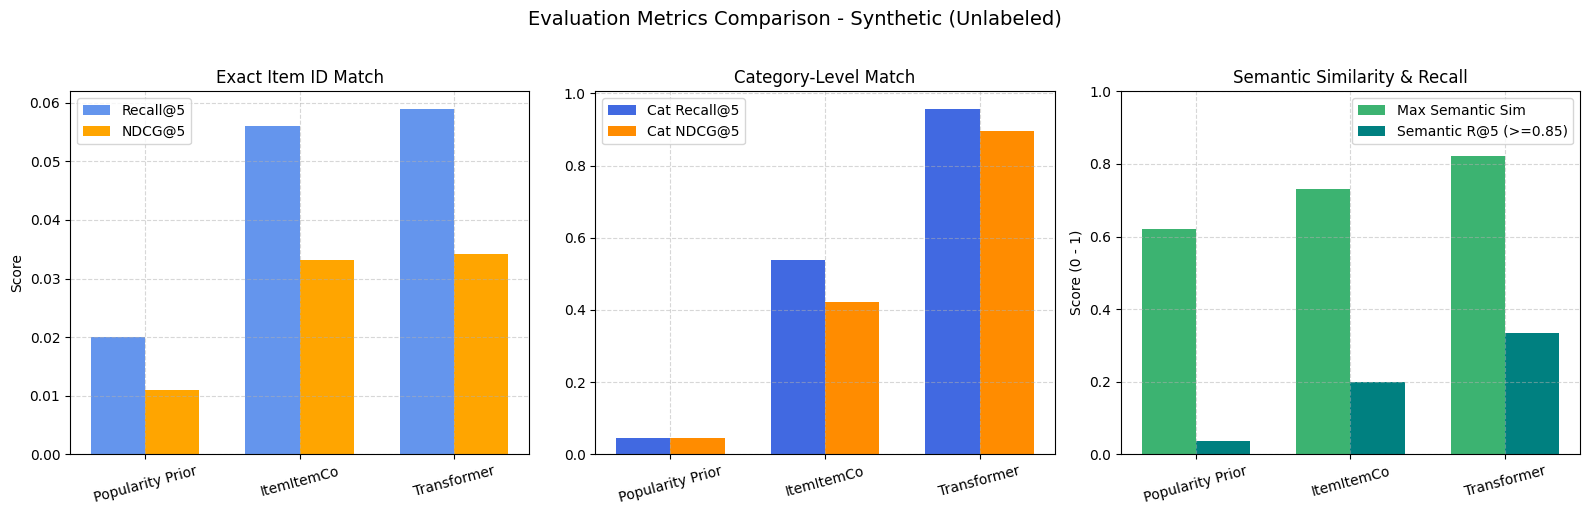

In [9]:
def get_and_display_metrics(dataset: str = "df_captions", labeled: bool = False, k: int = 10, max_val_rooms: int = 200, trans_model_override: str = None, aggregation: str = "sampled_interleaved", similarity_threshold: float = 0.85, pop_weight: float = 0.05):
    # 1. Determine the appropriate model checkpoint and catalog metadata
    label_tag = "labeled" if labeled else "unlabeled"
    if dataset == "df_captions":
        trans_model_filename = f"df_captions_{label_tag}.pt"
        csv_path = ROOT / "data" / "df_captions.csv"
    elif dataset == "df_short":
        trans_model_filename = f"df_short_{label_tag}.pt"
        csv_path = ROOT / "data" / "df_short.csv"
    else:
        trans_model_filename = f"synthetic_{label_tag}.pt"
        csv_path = ROOT / "data" / "processed_ikea_data.csv"

    trans_model_filename = trans_model_filename if trans_model_override is None else trans_model_override

    model_unlabeled = FurnitureEmbeddingPredictor(nhead=4, num_candidates=NUM_HEADS, num_layers=NUM_LAYERS, hid_dim=HID_DIM)
    model_path = ROOT / "notebooks" / trans_model_filename
    if not model_path.exists():
        raise FileNotFoundError(f"Model checkpoint not found on disk: {model_path}")
    
    print(f"Loading weights from {trans_model_filename}...")
    model_unlabeled.load_state_dict(torch.load(str(model_path), weights_only=True))
    
    # 2. Load dataset using the specified dataset parameter
    train_dataset = RoomDataset("train", labeled=labeled, dataset=dataset)
    val_dataset = RoomDataset("val", labeled=labeled, dataset=dataset)
    rooms_train = [room["item_ids"] for room in train_dataset.rooms]
    val_rooms_filtered = [room for room in val_dataset.rooms if len(room["item_ids"]) >= 2]
    if labeled:
        rooms_val = [[room["room_type"].replace("_", " ")] + room["item_ids"] for room in val_rooms_filtered]
    else:
        rooms_val = [room["item_ids"] for room in val_rooms_filtered]
    
    if max_val_rooms is not None:
        rooms_val = rooms_val[:max_val_rooms]

    # 3. Build category mapping from catalog metadata
    df = pd.read_csv(csv_path)
    cat_map = dict(zip(df["item_id"].astype(int), df["category"].astype(str)))
    emb_map = val_dataset.item_embeddings

    # 4. Instantiate models
    trans_evaluator = TransformerEvaluator(
        model=model_unlabeled,
        item_embeddings=val_dataset.item_embeddings,  # dict: {item_id: Tensor(384)}
        aggregation=aggregation,
        train_rooms=rooms_train,
        pop_weight=pop_weight,
        room_type_embeddings=val_dataset.room_type_embeddings if labeled else None,
    )
    baseline_train_data = train_dataset.rooms if labeled else rooms_train
    pop_model = PopularityPrior()
    pop_model.fit(baseline_train_data)
    iic_model = ItemItemCooccurrence()
    iic_model.fit(baseline_train_data)
    content_model = ItemContentBaseline(
        item_id=list(emb_map.keys()),
        item_embeddings=emb_map,
        room_type_embeddings=val_dataset.room_type_embeddings if labeled else None,
    )

    # 5. Evaluate all models using the enhanced LeaveOneOutEvaluator
    loo_evaluator = LeaveOneOutEvaluator(
        k=k,
        category_mapping=cat_map,
        embedding_mapping=emb_map,
        similarity_threshold=similarity_threshold,
    )

    print(f"\nEvaluating on {len(rooms_val)} validation rooms (k={k})...")
    print("Evaluating Popularity Prior...")
    res_pop = loo_evaluator.evaluate_all(pop_model, rooms_val, labeled=labeled)
    print("Evaluating Item Content...")
    res_content = loo_evaluator.evaluate_all(content_model, rooms_val, labeled=labeled)
    print("Evaluating Item-Item Co-occurrence...")
    res_iic = loo_evaluator.evaluate_all(iic_model, rooms_val, labeled=labeled)
    print("Evaluating Transformer...")
    res_trans = loo_evaluator.evaluate_all(trans_evaluator, rooms_val, labeled=labeled)

    # 6. Display Summary Comparison Table
    summary_df = pd.DataFrame([
        {
            "Model": "Popularity Prior",
            f"Exact R@{k}": f"{res_pop['exact_recall']:.4f}",
            f"Exact NDCG@{k}": f"{res_pop['exact_ndcg']:.4f}",
            f"Category R@{k}": f"{res_pop['category_recall']:.4f}",
            f"Category NDCG@{k}": f"{res_pop['category_ndcg']:.4f}",
            "Semantic Sim": f"{res_pop['semantic_similarity']:.4f}",
            f"Semantic R@{k}": f"{res_pop['semantic_recall']:.4f}",
        },
        {
            "Model": "ItemContent",
            f"Exact R@{k}": f"{res_content['exact_recall']:.4f}",
            f"Exact NDCG@{k}": f"{res_content['exact_ndcg']:.4f}",
            f"Category R@{k}": f"{res_content['category_recall']:.4f}",
            f"Category NDCG@{k}": f"{res_content['category_ndcg']:.4f}",
            "Semantic Sim": f"{res_content['semantic_similarity']:.4f}",
            f"Semantic R@{k}": f"{res_content['semantic_recall']:.4f}",
        },
        {
            "Model": "ItemItemCo",
            f"Exact R@{k}": f"{res_iic['exact_recall']:.4f}",
            f"Exact NDCG@{k}": f"{res_iic['exact_ndcg']:.4f}",
            f"Category R@{k}": f"{res_iic['category_recall']:.4f}",
            f"Category NDCG@{k}": f"{res_iic['category_ndcg']:.4f}",
            "Semantic Sim": f"{res_iic['semantic_similarity']:.4f}",
            f"Semantic R@{k}": f"{res_iic['semantic_recall']:.4f}",
        },
        {
            "Model": "Transformer",
            f"Exact R@{k}": f"{res_trans['exact_recall']:.4f}",
            f"Exact NDCG@{k}": f"{res_trans['exact_ndcg']:.4f}",
            f"Category R@{k}": f"{res_trans['category_recall']:.4f}",
            f"Category NDCG@{k}": f"{res_trans['category_ndcg']:.4f}",
            "Semantic Sim": f"{res_trans['semantic_similarity']:.4f}",
            f"Semantic R@{k}": f"{res_trans['semantic_recall']:.4f}",
        },
    ])
    print("\n--- Evaluation Summary Table ---")
    print(summary_df.to_string(index=False))

    # 7. Visualization: 3-panel comparative charts
    labels = ["Popularity Prior", "ItemContent", "ItemItemCo", "Transformer"]
    x = np.arange(len(labels))
    width = 0.35

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16, 5))

    # Subplot 1: Exact Item ID Metrics
    r_exact = [res_pop["exact_recall"], res_content["exact_recall"], res_iic["exact_recall"], res_trans["exact_recall"]]
    ndcg_exact = [res_pop["exact_ndcg"], res_content["exact_ndcg"], res_iic["exact_ndcg"], res_trans["exact_ndcg"]]
    ax1.bar(x - width / 2, r_exact, width, label=f"Recall@{k}", color="cornflowerblue")
    ax1.bar(x + width / 2, ndcg_exact, width, label=f"NDCG@{k}", color="orange")
    ax1.set_xticks(x)
    ax1.set_xticklabels(labels, rotation=15)
    ax1.set_title("Exact Item ID Match")
    ax1.set_ylabel("Score")
    ax1.legend()
    ax1.grid(True, linestyle="--", alpha=0.5)

    # Subplot 2: Category Match Metrics
    r_cat = [res_pop["category_recall"], res_content["category_recall"], res_iic["category_recall"], res_trans["category_recall"]]
    ndcg_cat = [res_pop["category_ndcg"], res_content["category_ndcg"], res_iic["category_ndcg"], res_trans["category_ndcg"]]
    ax2.bar(x - width / 2, r_cat, width, label=f"Cat Recall@{k}", color="royalblue")
    ax2.bar(x + width / 2, ndcg_cat, width, label=f"Cat NDCG@{k}", color="darkorange")
    ax2.set_xticks(x)
    ax2.set_xticklabels(labels, rotation=15)
    ax2.set_title("Category-Level Match")
    ax2.legend()
    ax2.grid(True, linestyle="--", alpha=0.5)

    # Subplot 3: Semantic Cosine Similarity & Semantic Recall
    sims = [res_pop["semantic_similarity"], res_content["semantic_similarity"], res_iic["semantic_similarity"], res_trans["semantic_similarity"]]
    sem_r = [res_pop["semantic_recall"], res_content["semantic_recall"], res_iic["semantic_recall"], res_trans["semantic_recall"]]
    ax3.bar(x - width / 2, sims, width, label="Max Semantic Sim", color="mediumseagreen")
    ax3.bar(x + width / 2, sem_r, width, label=f"Semantic R@{k} (>={similarity_threshold})", color="teal")
    ax3.set_xticks(x)
    ax3.set_xticklabels(labels, rotation=15)
    ax3.set_title("Semantic Similarity & Recall")
    ax3.set_ylabel("Score (0 - 1)")
    ax3.set_ylim(0.0, 1.0)
    ax3.legend()
    ax3.grid(True, linestyle="--", alpha=0.5)

    dataset_title = dataset.replace("_", " ").title()
    labeled_str = "Labeled" if labeled else "Unlabeled"
    fig.suptitle(f"Evaluation Metrics Comparison - {dataset_title} ({labeled_str})", fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()

dataset_metrics = "synthetic"
get_and_display_metrics(dataset=dataset_metrics, trans_model_override=None, k=5, labeled=True, max_val_rooms=1000, aggregation = "sampled_interleaved", similarity_threshold=.85, pop_weight=.5)
get_and_display_metrics(dataset=dataset_metrics, trans_model_override=None, k=5, labeled=False, max_val_rooms=1000, aggregation = "sampled_interleaved", similarity_threshold=.85, pop_weight=.5)

Loaded instance on device: mps with 13 candidate head(s)
Loading weights from df_captions_labeled.pt (aggregation=sampled_interleaved)...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Evaluating Popularity Prior up to k=20 on 1939 rooms...
Evaluating ItemContent up to k=20 on 1939 rooms...
Evaluating ItemItemCo up to k=20 on 1939 rooms...
Evaluating Transformer up to k=20 on 1939 rooms...


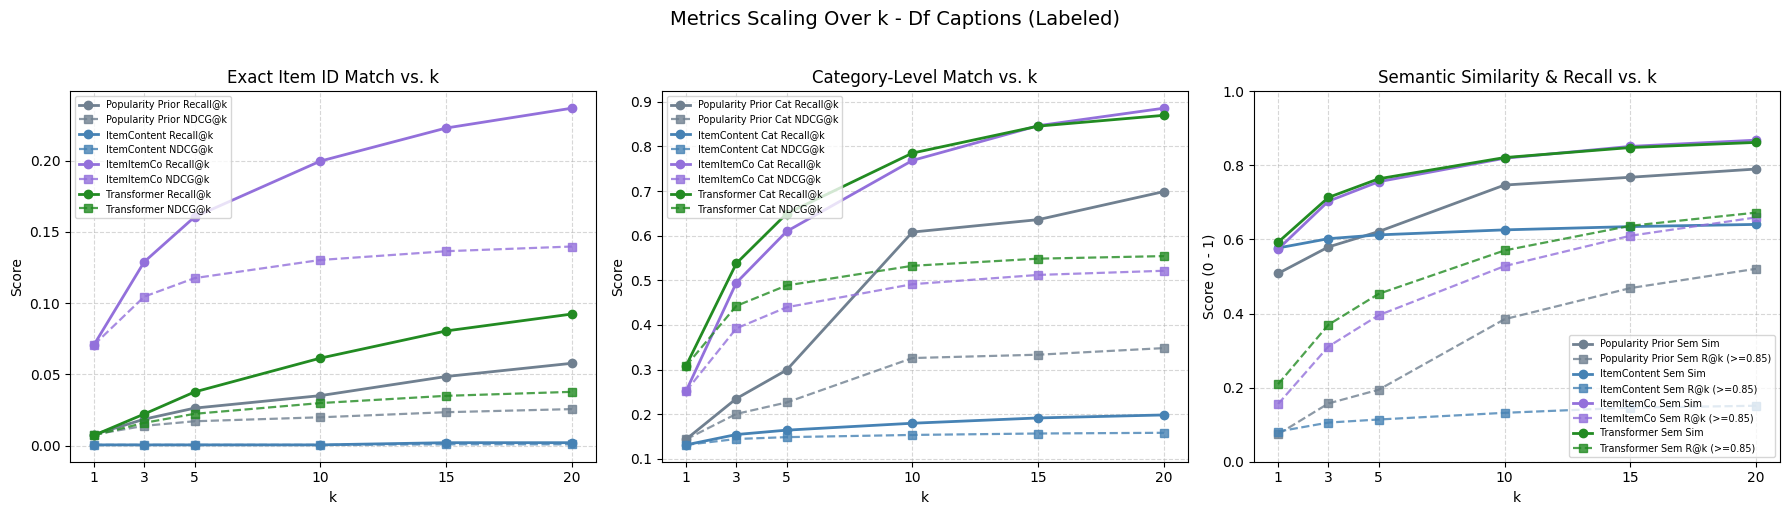

Loaded instance on device: mps with 13 candidate head(s)
Loading weights from df_captions_unlabeled.pt (aggregation=sampled_interleaved)...
Evaluating Popularity Prior up to k=20 on 1939 rooms...
Evaluating ItemContent up to k=20 on 1939 rooms...
Evaluating ItemItemCo up to k=20 on 1939 rooms...
Evaluating Transformer up to k=20 on 1939 rooms...


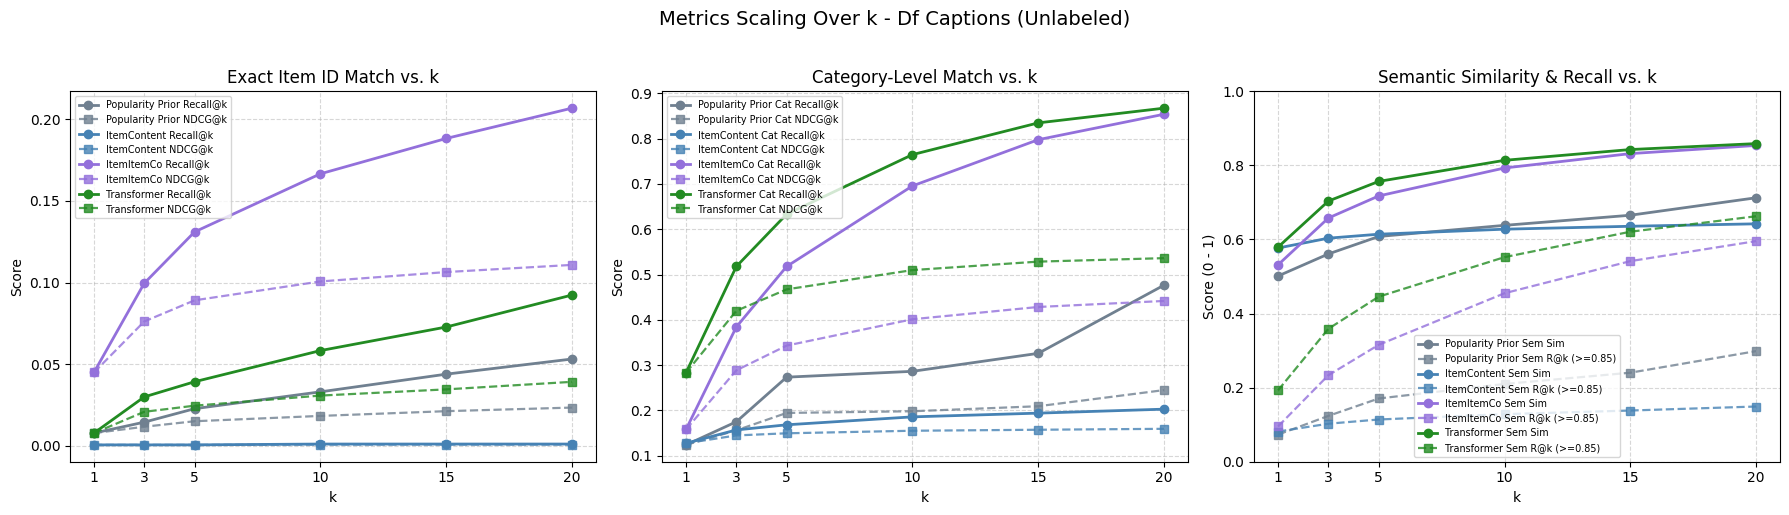

In [17]:
def plot_metrics_over_k(
    dataset: str = "df_captions",
    labeled: bool = False,
    k_values: list[int] = (1, 3, 5, 10, 15, 20),
    max_val_rooms: int = 200,
    trans_model_override: str = None,
    aggregation: str = "sampled_interleaved",
    similarity_threshold: float = 0.85,
    pop_weight: float = 0.05,
):
    import random
    from metrics import (
        recall_at_k,
        ndcg_at_k,
        category_recall_at_k,
        category_ndcg_at_k,
        semantic_similarity_at_k,
        semantic_recall_at_k,
    )

    k_values = sorted(k_values)
    max_k = max(k_values)

    # 1. Load checkpoint & metadata
    label_tag = "labeled" if labeled else "unlabeled"
    if dataset == "df_captions":
        trans_model_filename = f"df_captions_{label_tag}.pt"
        csv_path = ROOT / "data" / "df_captions.csv"
    elif dataset == "df_short":
        trans_model_filename = f"df_short_{label_tag}.pt"
        csv_path = ROOT / "data" / "df_short.csv"
    else:
        trans_model_filename = f"synthetic_{label_tag}.pt"
        csv_path = ROOT / "data" / "processed_ikea_data.csv"

    trans_model_filename = trans_model_filename if trans_model_override is None else trans_model_override

    model_unlabeled = FurnitureEmbeddingPredictor(
        nhead=4,
        num_candidates=NUM_HEADS,
        num_layers=NUM_LAYERS,
        hid_dim=HID_DIM,
    )
    model_path = ROOT / "notebooks" / trans_model_filename
    if not model_path.exists():
        raise FileNotFoundError(f"Model checkpoint not found on disk: {model_path}")

    print(f"Loading weights from {trans_model_filename} (aggregation={aggregation})...")
    model_unlabeled.load_state_dict(torch.load(str(model_path), weights_only=True))

    # 2. Load datasets & mappings
    train_dataset = RoomDataset("train", labeled=labeled, dataset=dataset)
    val_dataset = RoomDataset("val", labeled=labeled, dataset=dataset)
    rooms_train = [room["item_ids"] for room in train_dataset.rooms]
    val_rooms_filtered = [room for room in val_dataset.rooms if len(room["item_ids"]) >= 2]
    if labeled:
        rooms_val = [[room["room_type"].replace("_", " ")] + room["item_ids"] for room in val_rooms_filtered]
    else:
        rooms_val = [room["item_ids"] for room in val_rooms_filtered]
    if max_val_rooms is not None:
        rooms_val = rooms_val[:max_val_rooms]

    df = pd.read_csv(csv_path)
    cat_map = dict(zip(df["item_id"].astype(int), df["category"].astype(str)))
    emb_map = val_dataset.item_embeddings

    # 3. Instantiate models
    trans_evaluator = TransformerEvaluator(
        model=model_unlabeled,
        item_embeddings=emb_map,
        aggregation=aggregation,
        train_rooms=rooms_train,
        pop_weight=pop_weight,
        room_type_embeddings=val_dataset.room_type_embeddings if labeled else None,
    )
    baseline_train_data = train_dataset.rooms if labeled else rooms_train
    pop_model = PopularityPrior()
    pop_model.fit(baseline_train_data)
    iic_model = ItemItemCooccurrence()
    iic_model.fit(baseline_train_data)
    content_model = ItemContentBaseline(
        item_id=list(emb_map.keys()),
        item_embeddings=emb_map,
        room_type_embeddings=val_dataset.room_type_embeddings if labeled else None,
    )

    models = {
        "Popularity Prior": pop_model,
        "ItemContent": content_model,
        "ItemItemCo": iic_model,
        "Transformer": trans_evaluator,
    }

    # 4. Compute predictions once at max_k per room and score across all k_values
    results = {
        name: {
            k: {"exact_recall": 0.0, "exact_ndcg": 0.0, "cat_recall": 0.0, "cat_ndcg": 0.0, "sem_sim": 0.0, "sem_recall": 0.0}
            for k in k_values
        }
        for name in models
    }

    for name, model in models.items():
        print(f"Evaluating {name} up to k={max_k} on {len(rooms_val)} rooms...")
        random.seed(42)
        valid_rooms = 0
        for room in rooms_val:
            if len(room) < 2:
                continue
            room_copy = room.copy()
            idx = random.randint(1 if labeled else 0, len(room_copy) - 1)
            target_item = room_copy.pop(idx)
            preds = model.predict(room_copy, k=max_k)

            for k in k_values:
                results[name][k]["exact_recall"] += recall_at_k(preds, target_item, k)
                results[name][k]["exact_ndcg"] += ndcg_at_k(preds, target_item, k)
                results[name][k]["cat_recall"] += category_recall_at_k(preds, target_item, cat_map, k)
                results[name][k]["cat_ndcg"] += category_ndcg_at_k(preds, target_item, cat_map, k)
                results[name][k]["sem_sim"] += semantic_similarity_at_k(preds, target_item, emb_map, k)
                results[name][k]["sem_recall"] += semantic_recall_at_k(preds, target_item, emb_map, k, threshold=similarity_threshold)
            valid_rooms += 1

        if valid_rooms > 0:
            for k in k_values:
                for metric in results[name][k]:
                    results[name][k][metric] /= valid_rooms

    # 5. Plot 3 subplots over k
    colors = {
        "Popularity Prior": "slategray",
        "ItemContent": "steelblue",
        "ItemItemCo": "mediumpurple",
        "Transformer": "forestgreen",
    }

    fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

    for name in models:
        c = colors[name]
        ex_r = [results[name][k]["exact_recall"] for k in k_values]
        ex_n = [results[name][k]["exact_ndcg"] for k in k_values]
        cat_r = [results[name][k]["cat_recall"] for k in k_values]
        cat_n = [results[name][k]["cat_ndcg"] for k in k_values]
        sem_s = [results[name][k]["sem_sim"] for k in k_values]
        sem_r = [results[name][k]["sem_recall"] for k in k_values]

        # Subplot 1: Exact ID Recall & NDCG
        ax1.plot(k_values, ex_r, marker="o", linestyle="-", color=c, linewidth=2, label=f"{name} Recall@k")
        ax1.plot(k_values, ex_n, marker="s", linestyle="--", color=c, linewidth=1.6, alpha=0.8, label=f"{name} NDCG@k")

        # Subplot 2: Category Recall & NDCG
        ax2.plot(k_values, cat_r, marker="o", linestyle="-", color=c, linewidth=2, label=f"{name} Cat Recall@k")
        ax2.plot(k_values, cat_n, marker="s", linestyle="--", color=c, linewidth=1.6, alpha=0.8, label=f"{name} Cat NDCG@k")

        # Subplot 3: Max Semantic Cosine Similarity & Semantic Recall
        ax3.plot(k_values, sem_s, marker="o", linestyle="-", color=c, linewidth=2, label=f"{name} Sem Sim")
        ax3.plot(k_values, sem_r, marker="s", linestyle="--", color=c, linewidth=1.6, alpha=0.8, label=f"{name} Sem R@k (>={similarity_threshold})")

    ax1.set_title("Exact Item ID Match vs. k")
    ax1.set_xlabel("k")
    ax1.set_ylabel("Score")
    ax1.set_xticks(k_values)
    ax1.grid(True, linestyle="--", alpha=0.5)
    ax1.legend(fontsize="x-small")

    ax2.set_title("Category-Level Match vs. k")
    ax2.set_xlabel("k")
    ax2.set_ylabel("Score")
    ax2.set_xticks(k_values)
    ax2.grid(True, linestyle="--", alpha=0.5)
    ax2.legend(fontsize="x-small")

    ax3.set_title("Semantic Similarity & Recall vs. k")
    ax3.set_xlabel("k")
    ax3.set_ylabel("Score (0 - 1)")
    ax3.set_xticks(k_values)
    ax3.set_ylim(0.0, 1.0)
    ax3.grid(True, linestyle="--", alpha=0.5)
    ax3.legend(fontsize="x-small")

    dataset_title = dataset.replace("_", " ").title()
    labeled_str = "Labeled" if labeled else "Unlabeled"
    fig.suptitle(f"Metrics Scaling Over k - {dataset_title} ({labeled_str})", fontsize=14, y=1.02)
    plt.tight_layout()
    plt.show()


plot_metrics_over_k(dataset="df_captions", labeled=True, k_values=[1, 3, 5, 10, 15, 20], max_val_rooms=2000, aggregation="sampled_interleaved", pop_weight=.5)
plot_metrics_over_k(dataset="df_captions", labeled=False, k_values=[1, 3, 5, 10, 15, 20], max_val_rooms=2000, aggregation="sampled_interleaved", pop_weight=.5)

Loaded instance on device: mps with 13 candidate head(s)
Loading weights from df_captions_labeled.pt (aggregation=interleaved)...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Evaluating Popularity Prior at k=5 across 11 thresholds...
Evaluating ItemItemCo at k=5 across 11 thresholds...
Evaluating Transformer at k=5 across 11 thresholds...


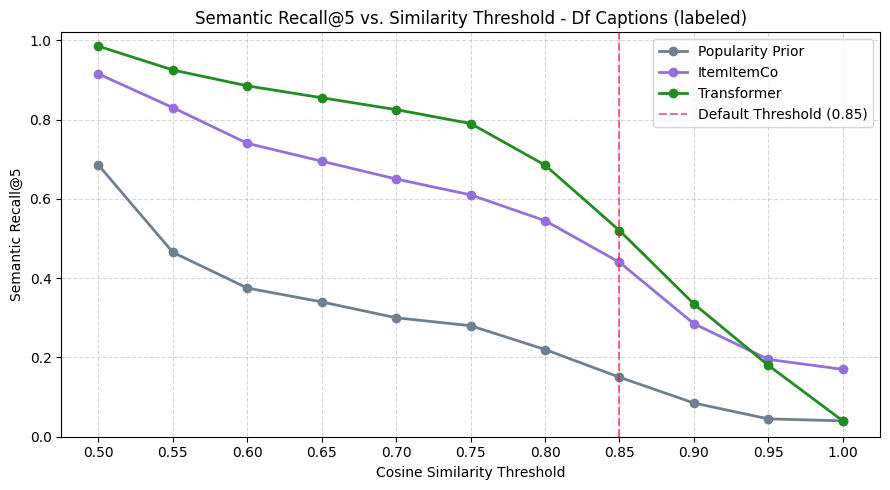

Loaded instance on device: mps with 13 candidate head(s)
Loading weights from df_captions_unlabeled.pt (aggregation=interleaved)...
Evaluating Popularity Prior at k=5 across 11 thresholds...
Evaluating ItemItemCo at k=5 across 11 thresholds...
Evaluating Transformer at k=5 across 11 thresholds...


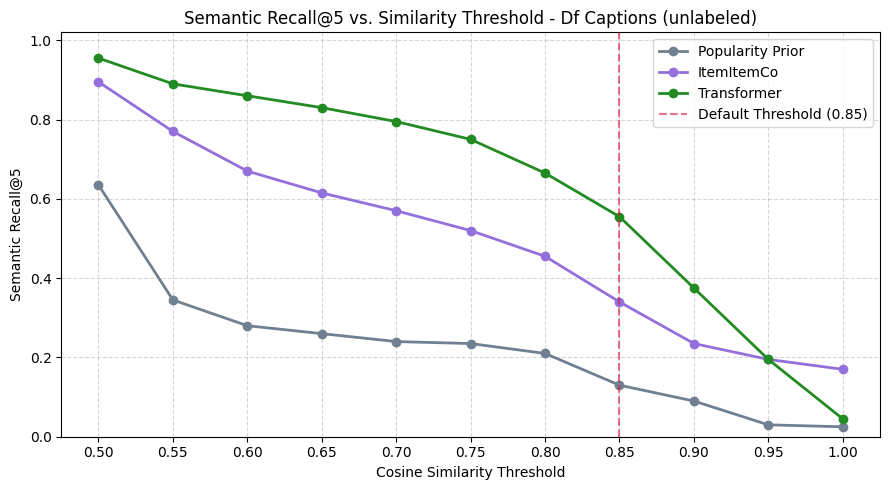

In [8]:
def plot_semantic_recall_over_threshold(
    dataset: str = "df_captions",
    labeled: bool = False,
    k: int = 10,
    thresholds: list[float] = None,
    max_val_rooms: int = 200,
    trans_model_override: str = None,
    aggregation: str = "sampled_interleaved",
    pop_weight: float = 0.05,
):
    import random
    from metrics import recall_at_k, semantic_similarity_at_k

    if thresholds is None:
        thresholds = [round(0.50 + 0.05 * i, 2) for i in range(11)]

    # 1. Load checkpoint & metadata
    label_tag = "labeled" if labeled else "unlabeled"
    if dataset == "df_captions":
        trans_model_filename = f"df_captions_{label_tag}.pt"
    elif dataset == "df_short":
        trans_model_filename = f"df_short_{label_tag}.pt"
    else:
        trans_model_filename = f"synthetic_{label_tag}.pt"

    trans_model_filename = trans_model_filename if trans_model_override is None else trans_model_override

    model_unlabeled = FurnitureEmbeddingPredictor(
        nhead=4,
        num_candidates=NUM_HEADS,
        num_layers=NUM_LAYERS,
        hid_dim=HID_DIM,
    )
    model_path = ROOT / "notebooks" / trans_model_filename
    if not model_path.exists():
        raise FileNotFoundError(f"Model checkpoint not found on disk: {model_path}")

    print(f"Loading weights from {trans_model_filename} (aggregation={aggregation})...")
    model_unlabeled.load_state_dict(torch.load(str(model_path), weights_only=True))

    # 2. Load datasets & embeddings
    train_dataset = RoomDataset("train", labeled=labeled, dataset=dataset)
    val_dataset = RoomDataset("val", labeled=labeled, dataset=dataset)
    rooms_train = [room["item_ids"] for room in train_dataset.rooms]
    val_rooms_filtered = [room for room in val_dataset.rooms if len(room["item_ids"]) >= 2]
    if labeled:
        rooms_val = [[room["room_type"].replace("_", " ")] + room["item_ids"] for room in val_rooms_filtered]
    else:
        rooms_val = [room["item_ids"] for room in val_rooms_filtered]
    if max_val_rooms is not None:
        rooms_val = rooms_val[:max_val_rooms]

    emb_map = val_dataset.item_embeddings

    # 3. Instantiate models
    trans_evaluator = TransformerEvaluator(
        model=model_unlabeled,
        item_embeddings=emb_map,
        aggregation=aggregation,
        train_rooms=rooms_train,
        pop_weight=pop_weight,
        room_type_embeddings=val_dataset.room_type_embeddings if labeled else None,
    )
    baseline_train_data = train_dataset.rooms if labeled else rooms_train
    pop_model = PopularityPrior()
    pop_model.fit(baseline_train_data)
    iic_model = ItemItemCooccurrence()
    iic_model.fit(baseline_train_data)
    content_model = ItemContentBaseline(
        item_id=list(emb_map.keys()),
        item_embeddings=emb_map,
        room_type_embeddings=val_dataset.room_type_embeddings if labeled else None,
    )

    models = {
        "Popularity Prior": pop_model,
        "ItemContent": content_model,
        "ItemItemCo": iic_model,
        "Transformer": trans_evaluator,
    }

    # 4. Run prediction once per room and sweep thresholds
    scores = {name: [0.0] * len(thresholds) for name in models}

    for name, model in models.items():
        print(f"Evaluating {name} at k={k} across {len(thresholds)} thresholds...")
        random.seed(42)
        valid_rooms = 0
        for room in rooms_val:
            if len(room) < 2:
                continue
            room_copy = room.copy()
            idx = random.randint(1 if labeled else 0, len(room_copy) - 1)
            target_item = room_copy.pop(idx)
            preds = model.predict(room_copy, k=k)

            exact_hit = recall_at_k(preds, target_item, k) == 1.0
            max_sim = semantic_similarity_at_k(preds, target_item, emb_map, k)

            for ti, thresh in enumerate(thresholds):
                if exact_hit or max_sim >= thresh:
                    scores[name][ti] += 1.0
            valid_rooms += 1

        if valid_rooms > 0:
            scores[name] = [s / valid_rooms for s in scores[name]]

    # 5. Plot
    colors = {
        "Popularity Prior": "slategray",
        "ItemContent": "steelblue",
        "ItemItemCo": "mediumpurple",
        "Transformer": "forestgreen",
    }

    fig, ax = plt.subplots(figsize=(9, 5))
    for name in models:
        ax.plot(thresholds, scores[name], marker="o", linewidth=2, color=colors[name], label=name)

    ax.axvline(0.85, color="crimson", linestyle="--", alpha=0.6, label="Default Threshold (0.85)")
    ax.set_title(f"Semantic Recall@{k} vs. Similarity Threshold - {dataset.replace('_', ' ').title()} ({"labeled" if labeled else "unlabeled"})")
    ax.set_xlabel("Cosine Similarity Threshold")
    ax.set_ylabel(f"Semantic Recall@{k}")
    ax.set_xticks(thresholds)
    ax.set_ylim(0.0, 1.02)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend()
    plt.tight_layout()
    plt.show()

plot_semantic_recall_over_threshold(dataset="df_captions", labeled=True, k=5, max_val_rooms=200, aggregation="interleaved")
plot_semantic_recall_over_threshold(dataset="df_captions", labeled=False, k=5, max_val_rooms=200, aggregation="interleaved")